# Padding for the wavelet response

The wavelet response needs the record it runs on to be zero padded, and this
notebook explains how much, why that much, and how the package expresses it.

The short version:

- pad **$\lceil L/2 \rceil$ wavelet rows at each end**, where $L$ is the
  response's `max_lag_L`;
- one row is $\Delta T / \delta t = N_f$ samples;
- nothing is applied for you - padding is always the caller's decision.

The one thing to take away is *why it is $L/2$ and not $L$*: because you pad
**both** ends.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp

import WDM
from WDM_LISAresponse.code.utils import utils
from WDM_LISAresponse.code.waveforms import waveforms
from WDM_LISAresponse.code.lisa_response.response import LISAresponse
from lisaorbits import EqualArmlengthOrbits

dt = 5.0        # sample cadence [s]
Nf = 16         # WDM frequency bands
q = 8           # WDM truncation parameter
L = 25          # max retained lag in the response filter tables
N_signal = 1024 # unpadded signal length [samples]

print(f"one wavelet row = Nf = {Nf} samples = dT = {Nf*dt:.0f} s")
print(f"the signal is {N_signal} samples = {N_signal//Nf} rows")

one wavelet row = Nf = 16 samples = dT = 80 s
the signal is 1024 samples = 64 rows


## 1. Why padding is needed at all

`LISAresponse` moves each wavelet pixel to its retarded phase using
`WDM_transform.apply_variable_time_shift`. That operator **wraps
periodically** at the ends of the record instead of running off it, so power
leaving one end reappears at the other.

How far does it reach? Row $n$ of the output reads rows $n-L \ldots n+L$ of
the input. Put an impulse in a single row and look at where it lands.

an impulse in one row reaches 25 rows away, and exactly zero beyond


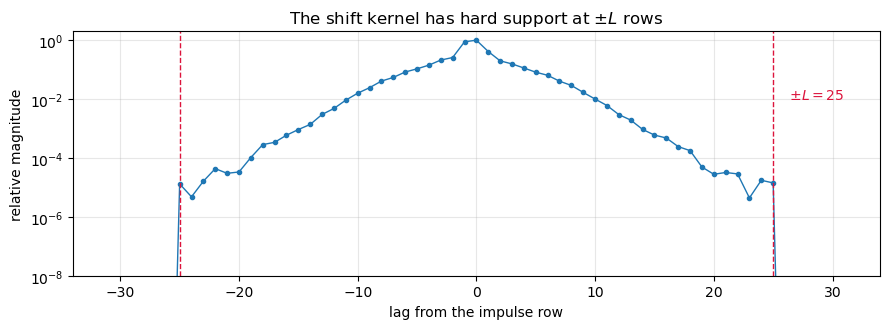

In [2]:
w_probe = WDM.WDM.WDM_transform(dt=dt, Nf=Nf, N=Nf*64, q=q)
tables = w_probe.build_time_delay_filter_interpolants(L, 16)

impulse = jnp.zeros((64, Nf)).at[0, :].set(1.0)
shifted = np.asarray(w_probe.apply_variable_time_shift(
    tables, impulse, jnp.full((64,), 0.37 * w_probe.dT)))

row_amp = np.abs(shifted).max(axis=1)
row_amp /= row_amp.max()
lags = np.where(np.arange(64) <= 32, np.arange(64), np.arange(64) - 64)

order = np.argsort(lags)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.semilogy(lags[order], np.maximum(row_amp[order], 1e-20), ".-", lw=1)
for s in (-L, L):
    ax.axvline(s, color="crimson", ls="--", lw=1)
ax.text(L + 1, 1e-2, f" $\\pm L = {L}$", color="crimson")
ax.set(xlabel="lag from the impulse row", ylabel="relative magnitude",
       title="The shift kernel has hard support at $\\pm L$ rows",
       xlim=(-34, 34), ylim=(1e-8, 2))
ax.grid(alpha=.3)
fig.tight_layout()

reach = np.abs(lags[row_amp > 0]).max()
print(f"an impulse in one row reaches {reach} rows away, and exactly zero beyond")

The kernel has **hard support at $\pm L$** and is exactly zero beyond. So on
an *unpadded* record the first $L$ and last $L$ rows are contaminated by
material wrapped from the other end.

## 2. Why $\lceil L/2 \rceil$ is enough

The instinct is to pad $L$ rows. You only need half that, and the reason is
that you pad *both* ends.

Let $P$ be the rows of zero padding at each end. The first physical row sits
at index $P$, and it reads down to row $P - L$. That is negative, so it wraps
to $N_t + P - L$. The trailing pad occupies rows $N_t - P$ onwards, so the
wrapped read lands **inside the trailing pad** whenever

$$N_t + P - L \geq N_t - P \quad \Longleftrightarrow \quad P \geq L/2 .$$

The wrapped read still happens. It just returns zeros. Pad one end only and
you would need the full $L$.

## 3. What `wdm_padding_info` does

| | requirement | why |
|---|---|---|
| **tiling** | total length a multiple of $2N_f$ | `WDM_transform` needs $N_t$ even |
| **wrap** | $\lceil L/2 \rceil$ rows *each* end | section 2 - this is the one that matters |

Padding is quantised to whole rows so the signal starts on a row boundary.
That is what lets `wdm_cut_info` recover the original span by exact integer
slicing later, instead of converting samples to rows with a ceiling.

> *Small print.* The leading pad is also rounded up to an **even** number of
> rows. This is bookkeeping, not correctness: the basis alternates cosine-like
> and sine-like packets along the time axis, so a signal at an odd row offset
> is measured against the other kind - exactly and reversibly, but as different
> numbers, which stops two differently padded grids being compared coefficient
> by coefficient. It costs at most one row and changes no response.

## 4. Decide, then apply

The padding functions split into **deciders** (pure arithmetic, no arrays) and
**appliers** (nothing but indexing):

```
                 decide                  apply
going in    wdm_padding_info   ->   apply_zero_padding    (time domain)
coming out  wdm_cut_info       ->   apply_wdm_cut         (wavelet domain)
```

`wdm_padding_info` takes a *length*, not an array. That is deliberate: it
means the same plan can be applied to a single noise series, one polarisation,
or several records that must land on the same grid.

In [3]:
info = utils.wdm_padding_info(N_signal, Nf, max_lag_L=L)
for key, value in info.items():
    print(f"  {key:16s} {value}")

print(f"""
  guard_rows    = ceil(L/2) = ceil({L}/2)              = {info['guard_rows']}
  rows_left     = {info['guard_rows']}, rounded up to even            = {info['rows_left']}
  pad_left      = rows_left * Nf = {info['rows_left']} * {Nf}          = {info['pad_left']}
  provisional   = {info['pad_left']} + {N_signal} + {info['guard_rows']}*{Nf}             = {info['pad_left'] + N_signal + info['guard_rows']*Nf}
  target_length = rounded up to a multiple of 2*Nf = {2*Nf}   = {info['target_length']}
  pad_right     = {info['target_length']} - {N_signal} - {info['pad_left']}           = {info['pad_right']}
  Nt            = {info['target_length']} / {Nf}                       = {info['Nt']}""")

  input_length     1024
  target_length    1472
  pad_left         224
  pad_right        224
  rows_left        14
  rows_right       14
  guard_rows       13
  Nf               16
  Nt               92

  guard_rows    = ceil(L/2) = ceil(25/2)              = 13
  rows_left     = 13, rounded up to even            = 14
  pad_left      = rows_left * Nf = 14 * 16          = 224
  provisional   = 224 + 1024 + 13*16             = 1456
  target_length = rounded up to a multiple of 2*Nf = 32   = 1472
  pad_right     = 1472 - 1024 - 224           = 224
  Nt            = 1472 / 16                       = 92


The returned dictionary holds one decision in **both unit systems** -
`pad_left`/`pad_right`/`target_length` in samples for the time series about to
be padded, `rows_left`/`rows_right`/`Nt` in rows for the coefficient grid that
will be cut. It is the only thing that crosses between the two domains, which
is why `wdm_cut_info` needs no arithmetic of its own.

Now apply it. Note that the generator does **no** padding: windows taper, they
do not pad.

generator returned 1024 samples - it does no padding
after padding:      1472 samples = 92 rows


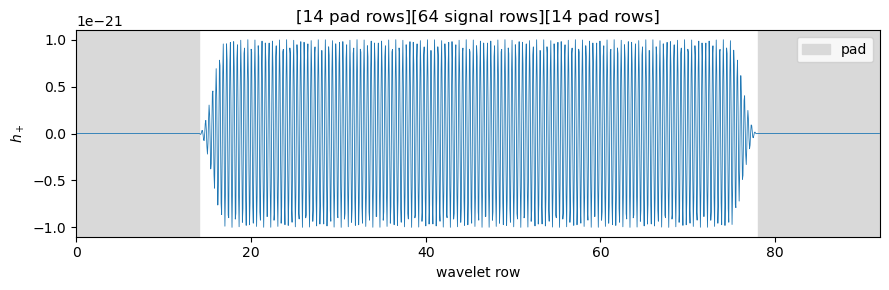

In [4]:
times, h_plus, h_cross = waveforms.generate_windowed_waveform(
    "monochromatic", t0=1.0e7, dt=dt, N=N_signal,
    model_kwargs=dict(A_plus=1.0e-21, A_cross=0.6e-21, f=0.031, phi_0=0.3),
    window_function="tukey", window_kwargs=dict(alpha=0.1))

print(f"generator returned {len(h_plus)} samples - it does no padding")

times, h_plus, h_cross = utils.apply_zero_padding(
    times, h_plus, h_cross, info["pad_left"], info["pad_right"])

print(f"after padding:      {len(h_plus)} samples = {info['Nt']} rows")

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(len(h_plus)) / Nf, h_plus, lw=.6)
for lo, hi, c, lab in [(0, info["rows_left"], "0.85", "pad"),
                       (info["Nt"] - info["rows_right"], info["Nt"], "0.85", None)]:
    ax.axvspan(lo, hi, color=c, label=lab)
ax.set(xlabel="wavelet row", ylabel="$h_+$", xlim=(0, info["Nt"]),
       title=f"[{info['rows_left']} pad rows][{N_signal//Nf} signal rows]"
             f"[{info['rows_right']} pad rows]")
ax.legend(loc="upper right")
fig.tight_layout()

## 5. Run the response

Build the transform with `N = info["target_length"]` and run it.

In [5]:
wdm = WDM.WDM.WDM_transform(dt=dt, Nf=Nf, N=info["target_length"], q=q)
response = LISAresponse(wdm, EqualArmlengthOrbits(), t0=float(times[0]), max_lag_L=L)

full = response(0.7, 1.3, wdm.dwt(jnp.asarray(h_plus)), wdm.dwt(jnp.asarray(h_cross)))
print(f"response on the padded grid: {full.shape}  = (links, Nt, Nf)")

response on the padded grid: (6, 92, 16)  = (links, Nt, Nf)


## 6. Cut the padding back off

`wdm_cut_info` reads the record and returns `slice` objects. They are returned
rather than applied because you usually want them for the time axis too.

`freq_slice` drops the $m=0$ band, which `WDM_LISAresponse` computes wrongly due to different time shift operators around $m=0$.

  wdm_Nt           92
  Nf               16
  rows_cut_left    14
  rows_cut_right   14
  time_slice       slice(14, 78, None)
  freq_slice       slice(1, None, None)

  (6, 92, 16)  ->  (6, 64, 15)
  the same slice trims the time axis: (64,)


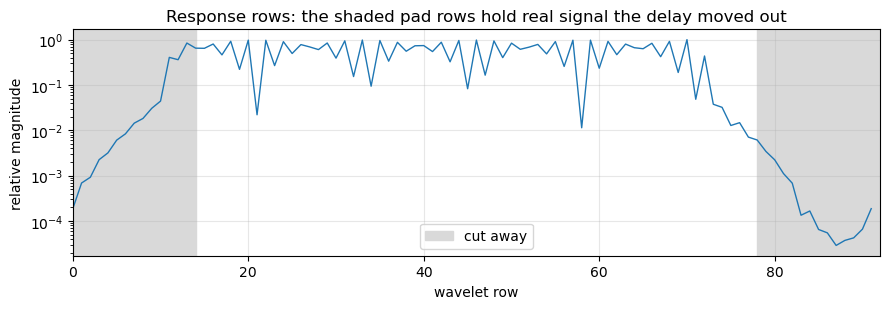

In [6]:
cut = utils.wdm_cut_info(info)
for key, value in cut.items():
    print(f"  {key:16s} {value}")

interior = utils.apply_wdm_cut(full, cut)
print(f"\n  {full.shape}  ->  {interior.shape}")

wavelet_times = np.asarray(response.wavelet_times)
print(f"  the same slice trims the time axis: {wavelet_times[cut['time_slice']].shape}")

profile = np.abs(np.asarray(full[0])).max(axis=1)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.semilogy(profile / profile.max(), lw=1)
ax.axvspan(0, info["rows_left"], color="0.85")
ax.axvspan(info["Nt"] - info["rows_right"], info["Nt"], color="0.85", label="cut away")
ax.set(xlabel="wavelet row", ylabel="relative magnitude", xlim=(0, info["Nt"]),
       title="Response rows: the shaded pad rows hold real signal the delay moved out")
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout()

Look at the shaded rows in that last plot. They are **not garbage**. With the
guard band in place nothing wrapped, and those rows hold genuine response -
signal that the delay carried outside the original record.

They are dropped because they have no counterpart in a differently padded run,
which is exactly what makes the next section possible.

## 7. Does it actually work?

If the guard band is doing its job, padding *beyond* it must change nothing.
Compare the interior against a heavily over-padded reference.

reference: 74 pad rows, Nt = 212

   extra  rows_left    Nt     mismatch      rel_L2


       0         14    92    2.666e-12   2.309e-06


       2         16    96    2.782e-12   2.359e-06


       4         18   100    2.070e-12   2.035e-06


       8         22   108    1.986e-12   1.993e-06


      16         30   124    1.960e-12   1.980e-06


      30         44   152    2.505e-12   2.238e-06


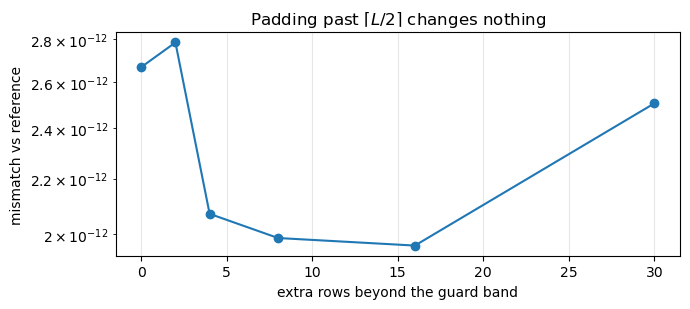

In [7]:
def interior_for(extra_rows):
    t, hp, hc = waveforms.generate_windowed_waveform(
        "monochromatic", t0=1.0e7, dt=dt, N=N_signal,
        model_kwargs=dict(A_plus=1.0e-21, A_cross=0.6e-21, f=0.031, phi_0=0.3),
        window_function="tukey", window_kwargs=dict(alpha=0.1))
    plan = utils.wdm_padding_info(len(t), Nf, max_lag_L=L,
                                  extra_rows_left=extra_rows,
                                  extra_rows_right=extra_rows)
    t, hp, hc = utils.apply_zero_padding(t, hp, hc, plan["pad_left"], plan["pad_right"])
    tf = WDM.WDM.WDM_transform(dt=dt, Nf=Nf, N=plan["target_length"], q=q)
    r = LISAresponse(tf, EqualArmlengthOrbits(), t0=float(t[0]), max_lag_L=L)
    out = r(0.7, 1.3, tf.dwt(jnp.asarray(hp)), tf.dwt(jnp.asarray(hc)))
    return np.asarray(utils.apply_wdm_cut(out, utils.wdm_cut_info(plan))), plan

reference, ref_plan = interior_for(60)
print(f"reference: {ref_plan['rows_left']} pad rows, Nt = {ref_plan['Nt']}\n")
print(f"  {'extra':>6} {'rows_left':>10} {'Nt':>5} {'mismatch':>12} {'rel_L2':>11}")

extras, mismatches = [0, 2, 4, 8, 16, 30], []
for extra in extras:
    trial, plan = interior_for(extra)
    m = utils.wdm_mismatch(reference, trial)
    mismatches.append(max(m["mismatch"], 1e-20))
    print(f"  {extra:>6} {plan['rows_left']:>10} {plan['Nt']:>5} "
          f"{m['mismatch']:>12.3e} {m['rel_L2']:>11.3e}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.semilogy(extras, mismatches, "o-")
ax.set(xlabel="extra rows beyond the guard band", ylabel="mismatch vs reference",
       title="Padding past $\\lceil L/2 \\rceil$ changes nothing")
ax.grid(alpha=.3)
fig.tight_layout()

Flat. The mismatch sits at $\sim 10^{-12}$ whatever extra padding is added,
which is the shift operator's own accuracy at $L = 25$ and nothing to do with
padding.

Now the other direction - what happens when there is **not enough**.

In [8]:
print(f"  {'guard rows used':>16} {'mismatch vs correct':>21}")
correct, _ = interior_for(0)
for used in [0, 2, 4, 6, 8, 10, 13]:
    t, hp, hc = waveforms.generate_windowed_waveform(
        "monochromatic", t0=1.0e7, dt=dt, N=N_signal,
        model_kwargs=dict(A_plus=1.0e-21, A_cross=0.6e-21, f=0.031, phi_0=0.3),
        window_function="tukey", window_kwargs=dict(alpha=0.1))
    plan = utils.wdm_padding_info(len(t), Nf, extra_rows_left=used, extra_rows_right=used)
    t, hp, hc = utils.apply_zero_padding(t, hp, hc, plan["pad_left"], plan["pad_right"])
    tf = WDM.WDM.WDM_transform(dt=dt, Nf=Nf, N=plan["target_length"], q=q)
    r = LISAresponse(tf, EqualArmlengthOrbits(), t0=float(t[0]), max_lag_L=L)
    out = r(0.7, 1.3, tf.dwt(jnp.asarray(hp)), tf.dwt(jnp.asarray(hc)))
    trial = np.asarray(utils.apply_wdm_cut(out, utils.wdm_cut_info(plan)))
    n = min(trial.shape[-2], correct.shape[-2])
    m = utils.wdm_mismatch(correct[..., :n, :], trial[..., :n, :])
    print(f"  {plan['rows_left']:>16} {m['mismatch']:>21.3e}")

   guard rows used   mismatch vs correct


                 0             1.519e-02


                 2             4.276e-05


                 4             1.305e-06


                 6             1.104e-08


                 8             1.984e-10


                10             5.040e-11


                14             0.000e+00


That is the whole argument in one table. With no guard band the mismatch is
$1.5\times10^{-2}$; it falls monotonically as rows are added and reaches
**exactly zero** at $\lceil L/2 \rceil$ rounded to even. Not approximately
zero - the wrapped reads are landing on zeros, so the answer is identical.

More padding is wasted memory. Less is wrong.

## 8. The time-domain path needs none of this

`one_arm_response_time_domain` has no wrap to guard against and no tiling to
satisfy. It needs only whatever margin you judge right, in samples, so
`apply_zero_padding` is the whole story.

In [9]:
t_td, hp_td, hc_td = waveforms.generate_windowed_waveform(
    "linear_freq", t0=1.0e7, dt=dt, N=512,
    model_kwargs=dict(A_plus=1.0e-21, A_cross=0.0, f_start=0.02, f_end=0.03, phi_0=0.0),
    window_function="tukey", window_kwargs=dict(alpha=0.1))

t_td, hp_td, hc_td = utils.apply_zero_padding(t_td, hp_td, hc_td, 500, 300)
print(f"512 samples -> {len(t_td)}, no rows, no tiling, no guard band")

512 samples -> 1312, no rows, no tiling, no guard band


## Summary

| function | role | domain |
|---|---|---|
| `wdm_padding_info` | **decides** the plan | both - samples and rows |
| `apply_zero_padding` | **applies** it | time |
| `wdm_cut_info` | **decides** where to cut | wavelet - rows and bands |
| `apply_wdm_cut` | **executes** the cut | wavelet |

```python
info = wdm_padding_info(len(times), Nf, max_lag_L=L)
times, h_plus, h_cross = apply_zero_padding(
    times, h_plus, h_cross, info["pad_left"], info["pad_right"])

# ... build WDM_transform(N=info["target_length"]), run the response ...

interior = apply_wdm_cut(response, wdm_cut_info(info))
```